# Automatic Higher or Lower Game Task

You need to implement an Automatic Higher or Lower Game.

Set the bounds to between 1 to 20. The Graph has to keep guessing (max number of guesses is 7) where if the guess is correct, then it stops, but if not we keep looping until we hit the max limit of 7.

Each time a number is guessed, the hint node should say higher or lower and the graph should account for this information and guess the next guess accordingly.

Input: {"player_name": "Student", "guesses": [], "attempts": 0, "lower_bound": 1, "upper_bound": 20}

Hint: It will need to adjust its bounds after every guess based on the hint provided by the hint node.

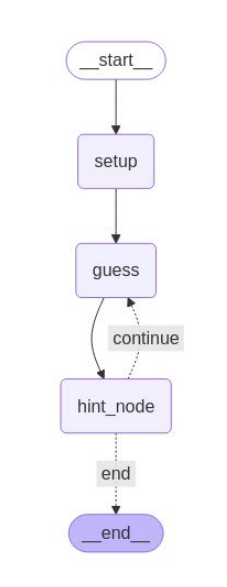

In [1]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END
import random

In [2]:
class AgentState(TypedDict):
    player_name: str
    guesses: List[int]
    attempts: 0
    lower_bound: 1
    upper_bound: 20
    target: int
    hint: str

In [ ]:
def setup_node(state: AgentState) -> AgentState:
    """setup the game by initializing the target"""
    
    state["target"] = random.randint(1, 20)
    print("Welcome to the Number Guessing Game!")
    print("Game started.")
    print(f"Welcome {state['player_name']}! I'm thinking of a number between 1 and 20.")
    return state

def guess_node(state: AgentState) -> AgentState:
    """generates a guess and updates the state accordingly"""
    possible_guesses = [i for i in range(state["lower_bound"], state["upper_bound"] + 1) if i not in state["guesses"]]

    if possible_guesses:
        guess = random.choice(possible_guesses)
    else:
        guess = random.randint(state["lower_bound"], state["upper_bound"])

    state["guesses"].append(guess)
    state["attempts"] += 1
    
    print(f"Attempt {state['attempts']}: Guessing {guess}. Current range: [{state['lower_bound']}, {state['upper_bound']}]")
    
    return state

def hint_node(state: AgentState) -> AgentState:
    """provides a hint based on the last guess and uppdate the bounds"""
    
    last_guess = state["guesses"][-1]
    target = state["target"]
    
    if last_guess < target:
        state["lower_bound"] = max(state["lower_bound"], last_guess + 1)
        state["hint"] = f"The guess {last_guess} is too low. Try a higher number."
        print(f"Hint: {state['hint']}")

    elif last_guess > target:
        state["upper_bound"] = min(state["upper_bound"], last_guess - 1)
        state["hint"] = f"The guess {last_guess} is too high. Try a lower number."
        print(f"Hint: {state['hint']}")

    else:
        state["hint"] = f"Correct! The number was {target}. You guessed it in {state['attempts']} attempts."
        print(f"Success: {state['hint']}")

    return state

def should_continue(state: AgentState) -> str:
    """determines whether to continue guessing or end the game"""

    last_guess = state["guesses"][-1]
    target = state["target"]

    if last_guess == target:
        print("GAME OVER: You've guessed the number!")
        return "end"
    elif state['attempts'] > 7:
        print(f"GAME OVER: You've exceeded the maximum number of attempts! The number was {target}.")
        return "end"
    else:
        print(f"CONTINUING: {state['attempts']}/7 attempts used. Keep guessing!")
        return "continue"
    

In [25]:
graph = StateGraph(AgentState)

graph.add_node(node='setup', action=setup_node)
graph.add_node(node='guess', action=guess_node)
graph.add_node(node='hint_node', action=hint_node)

graph.add_edge(START, 'setup')
graph.add_edge('setup', 'guess')
graph.add_edge('guess', 'hint_node')
graph.add_conditional_edges(
    'hint_node',
    should_continue,
    {
        'end': END,
        'continue': 'guess'
    }
)

app = graph.compile()

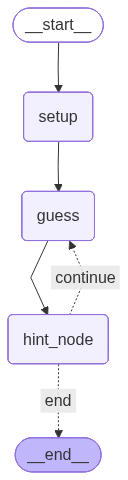

In [26]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [27]:
app.invoke({"player_name": "Alice", "guesses": [], "attempts": 0, "lower_bound": 1, "upper_bound": 20})

Welcome to the Number Guessing Game!
Game started.
Welcome Alice! I'm thinking of a number between 1 and 20. Can you guess it?
Attempt 1: Player guessed 15. Current range: [1, 20]
Hint: The guess 15 is too high. Try a lower number.
CONTINUING: 1/7 attempts used. Keep guessing!
Attempt 2: Player guessed 5. Current range: [1, 14]
Hint: The guess 5 is too high. Try a lower number.
CONTINUING: 2/7 attempts used. Keep guessing!
Attempt 3: Player guessed 1. Current range: [1, 4]
Hint: The guess 1 is too low. Try a higher number.
CONTINUING: 3/7 attempts used. Keep guessing!
Attempt 4: Player guessed 2. Current range: [2, 4]
Success: Correct! The number was 2. You guessed it in 4 attempts.
GAME OVER: You've guessed the number!


{'player_name': 'Alice',
 'guesses': [15, 5, 1, 2],
 'attempts': 4,
 'lower_bound': 2,
 'upper_bound': 4,
 'target': 2,
 'hint': 'Correct! The number was 2. You guessed it in 4 attempts.'}